In [70]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [99]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import sys
import os
cartella_src = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))

if cartella_src not in sys.path:
    sys.path.insert(0, cartella_src)
# 1. Importiamo i moduli custom dai file fisici
from Preprocessor import FullPipeline
from Regression.LinearRegression import LinearRegression

# 2. Caricamento e Preprocessing
print("Inizializzazione della FullPipeline...")
path_al_dataset = '../Dataset/AB_NYC_2019.csv'

pipeline = FullPipeline(path_al_dataset)
df_clean = pipeline.transform()
print(f"Dataset pulito. Shape: {df_clean.shape[0]} x {df_clean.shape[1]}")

# 3. Split e Scaling
X = df_clean.drop(columns=['log_price'])
y = df_clean['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 4. Addestramento del Modello (es. Lasso)
print("Addestramento del modello in corso...")
# Puoi testare penalty='l1' (Lasso), penalty='l2' (Ridge), o penalty=None (OLS standard)
model = LinearRegression(penalty='l1', alpha=0.0001) 
model.fit(X_train_scaled, y_train)

# 5. Previsione
y_pred_log = model.predict(X_test_scaled)

# 6. Valutazione Economica (riconversione da log a dollari)
y_test_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred_log)

rmse = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
r2 = r2_score(y_test, y_pred_log)

print(f"\n--- Risultati ---")
print(f"R^2 Score: {r2:.4f}")
print(f"RMSE (Errore Medio): ${rmse:.2f}")

# 7. Analisi dei Coefficienti
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficiente': model.coefficients
})

# Filtriamo solo le variabili che la Lasso ha mantenuto attive
driver_attivi = coef_df[coef_df['Coefficiente'] != 0].copy()
driver_attivi['Impatto'] = driver_attivi['Coefficiente'].abs()
driver_attivi = driver_attivi.sort_values(by='Impatto', ascending=False)

print("\n--- Top 10 Primary Drivers ---")
print(driver_attivi[['Feature', 'Coefficiente']].head(10))

Inizializzazione della FullPipeline...
Dataset pulito. Shape: 48869 x 17
Addestramento del modello in corso...

--- Risultati ---
R^2 Score: 0.5471
RMSE (Errore Medio): $100.64

--- Top 10 Primary Drivers ---
                           Feature  Coefficiente
10               room_type_ordinal      0.381061
7             distance_from_center     -0.228111
13   neighbourhood_group_Manhattan      0.107915
4                 availability_365      0.102863
12    neighbourhood_group_Brooklyn      0.091032
3   calculated_host_listings_count     -0.085618
0                   minimum_nights     -0.082826
9             host_is_professional      0.064473
11       listings_in_neighbourhood     -0.053034
8                 reviews_per_year     -0.042405


Si nota che la variabile che fa aumentare principalmente il prezzo è il tipo di stanza. Il coefficiente corrispondente è di 0.384798, questo significa che exp(0.384798)-1= 0.468, cioè che questa variabile può far aumentare il prezzo del 46.8%
Un discorso simile lo si applica per neighbourhood_group_Manhattan: lo stare vicino al centro di Manhattan auamenta il prezzo del 17.2%

R^2 è basso per la natura del dataset. Infatti questo non contiene informazioni circa la grandezza delle stanze e i vari servizi offerti con la stanza (piscina, tipologia di arredamento, etc.)


In [72]:
# Importa il nuovo modulo
from Regression.TreeRegression import TreeRegression

print("Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)")
# Inizializziamo con 100 alberi. Limitiamo la profondità a 20 per prevenire 
# che il modello impari a memoria il dataset di training (overfitting)
tree_model = TreeRegression(n_estimators=100, max_depth=20)

# Utilizziamo gli stessi dati già preparati precedentemente
tree_model.fit(X_train_scaled, y_train)

# Previsione e Valutazione
y_pred_log_tree = tree_model.predict(X_test_scaled)

# Riconversione in dollari
y_test_dollars = np.expm1(y_test)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test, y_pred_log_tree)

print(f"\n--- Risultati Random Forest ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE (Errore Medio): ${rmse_tree:.2f}")

# Analisi dell'importanza delle feature
importanza = pd.DataFrame({
    'Feature': X_train.columns,
    'Importanza': tree_model.feature_importances
})
importanza = importanza.sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 5) ---")
print(importanza.head(5))

Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)

--- Risultati Random Forest ---
R^2 Score: 0.6231
RMSE (Errore Medio): $91.84

--- Feature Importances (Top 5) ---
                                             Feature  Importanza
room_type_ordinal                  room_type_ordinal    0.430479
distance_from_center            distance_from_center    0.216556
minimum_nights                        minimum_nights    0.046591
listings_in_neighbourhood  listings_in_neighbourhood    0.045364
reviews_per_year                    reviews_per_year    0.041724


In [100]:
# Importa la nuova pipeline spaziale e il modello ad albero
from Preprocessor import TreePipeline
from Regression.TreeRegression import TreeRegression

print("1. Inizializzazione TreePipeline (con Coordinate Spaziali)...")
tree_pipeline = TreePipeline('../Dataset/AB_NYC_2019.csv')
df_tree = tree_pipeline.transform()

# 2. Split Feature/Target
X_tree = df_tree.drop(columns=['log_price'])
y_tree = df_tree['log_price']

# 3. Data Split (Nessuno StandardScaler applicato)
X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42
)

print("2. Addestramento Random Forest sui dati grezzi...")
tree_model = TreeRegression(n_estimators=100, max_depth=20)
tree_model.fit(X_train_tree, y_train_tree)

# 4. Previsioni e Riconversione
y_pred_log_tree = tree_model.predict(X_test_tree)
y_test_dollars = np.expm1(y_test_tree)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

# 5. Metriche
rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test_tree, y_pred_log_tree)

print(f"\n--- Risultati Random Forest (TreePipeline) ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE: ${rmse_tree:.2f}")

# 6. Analisi Importanza
importanza_tree = pd.DataFrame({
    'Feature': X_train_tree.columns,
    'Importanza': tree_model.feature_importances
}).sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 7) ---")
print(importanza_tree.head(7))

1. Inizializzazione TreePipeline (con Coordinate Spaziali)...
2. Addestramento Random Forest sui dati grezzi...

--- Risultati Random Forest (TreePipeline) ---
R^2 Score: 0.6302
RMSE: $91.23

--- Feature Importances (Top 7) ---
                                   Feature  Importanza
room_type_ordinal        room_type_ordinal    0.429602
distance_from_center  distance_from_center    0.166718
longitude                        longitude    0.082634
latitude                          latitude    0.053498
minimum_nights              minimum_nights    0.039977
reviews_per_year          reviews_per_year    0.033350
availability_365          availability_365    0.033071


La random forest ottiene riusltati migliori rispetto alla linear regression.

Il valore R quadro sale a 0.6282 utilizzando un dataset che contiene longitudine e latitudine in modo separato. 

Rimane evidente come la feature che causa il maggiore incremento del prezzo è la tipologia della stanza, seguito dalla posizione. Un altro indice importante si rivela essere il numero di recensioni per mese e totali, così anche come il fattore di notti minime.


Dati divisi in training (39095 righe) e test (9774 righe).
Dati divisi in training (39095 righe) e test (9774 righe).
Risultati 'linear': {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188}
OLS:   {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188}
Risultati 'linear': {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187}
Ridge: {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187}
Feature Selection completata: mantenute 16 variabili su 16.
Risultati 'linear': {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186}
Lasso: {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186}
Risultati 'tree': {'RMSE': np.float64(91.2263), 'MAE': 47.5371, 'R-squared': 0.4402}
RF:    {'RMSE': np.float64(91.2263), 'MAE': 47.5371, 'R-squared': 0.4402}
Calcolo della Validation Curve in corso...


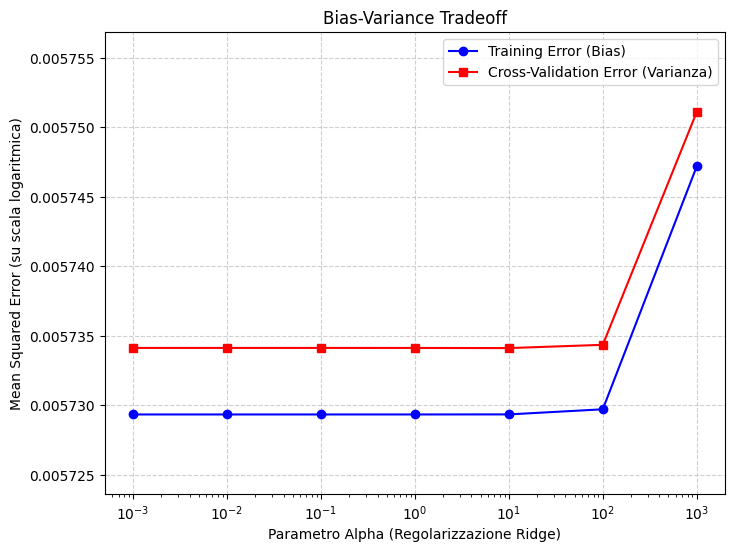

In [101]:
from Preprocessor import FullPipeline, TreePipeline
from MainRegression import Regression
from sklearn.model_selection import train_test_split

# --- 1. CARICA E PREPROCESSA ---

# Per i modelli lineari
pipeline_linear = FullPipeline("../Dataset/AB_NYC_2019.csv")
df_linear = pipeline_linear.transform()

# Per il Random Forest
pipeline_tree = TreePipeline("../Dataset/AB_NYC_2019.csv")
df_tree = pipeline_tree.transform()

# --- 2. ISTANZIA LA CLASSE REGRESSION ---

reg_linear = Regression(df_linear, target_column='log_price')
reg_tree   = Regression(df_tree,   target_column='log_price')

# --- 3. TESTA I MODELLI ---

# OLS (nessuna penalità)
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
print("OLS:  ", metrics_ols)

# Ridge
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=16.76833)
print("Ridge:", metrics_ridge)

# Lasso con feature selection
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.0001,
                                    use_feature_selection=True)
print("Lasso:", metrics_lasso)

# Random Forest
metrics_rf = reg_tree.evaluate(model_type='tree', n_estimators=100, max_depth=20)
print("RF:   ", metrics_rf)

# --- 4. BIAS-VARIANCE TRADEOFF ---
reg_linear.analyze_bias_variance()

In [98]:
# OLS
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
print("OLS:  ", metrics_ols)

# Ridge
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=16.76833)
print("Ridge:", metrics_ridge)

# Lasso con feature selection
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.0001,
                                    use_feature_selection=True)
print("Lasso:", metrics_lasso)

# Random Forest
metrics_rf = reg_tree.evaluate(model_type='tree', n_estimators=100, max_depth=20)
print("RF:   ", metrics_rf)

# # Feature Importance
# reg_linear.plot_feature_importance()

# # Bias-Variance Tradeoff
# reg_linear.analyze_bias_variance()

Risultati 'linear': {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188}
OLS:   {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188}
Risultati 'linear': {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187}
Ridge: {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187}
Feature Selection completata: mantenute 16 variabili su 16.
Risultati 'linear': {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186}
Lasso: {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186}
Risultati 'tree': {'RMSE': np.float64(91.2263), 'MAE': 47.5371, 'R-squared': 0.4402}
RF:    {'RMSE': np.float64(91.2263), 'MAE': 47.5371, 'R-squared': 0.4402}


# Slide Visualization

In [105]:

# 1. Modello Lineare Semplice (OLS)
ols_metrics = reg_linear.evaluate(model_type='linear', penalty=None)

# 2. Modello Ridge (userà alpha=16.76833 di default)
ridge_metrics = reg_linear.evaluate(model_type='linear', penalty='l2')

# 3. Modello Lasso (userà alpha=0.0001 di default)
lasso_metrics = reg_linear.evaluate(model_type='linear', penalty='l1')

# 4. Modello Random Forest
tree_metrics = reg_tree.evaluate(model_type='tree')


Risultati 'linear': {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188, 'R-squared (log)': 0.5471}
Risultati 'linear': {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187, 'R-squared (log)': 0.5471}
Risultati 'linear': {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186, 'R-squared (log)': 0.5471}
Risultati 'tree': {'RMSE': np.float64(91.2263), 'MAE': 47.5371, 'R-squared': 0.4402, 'R-squared (log)': 0.6302}


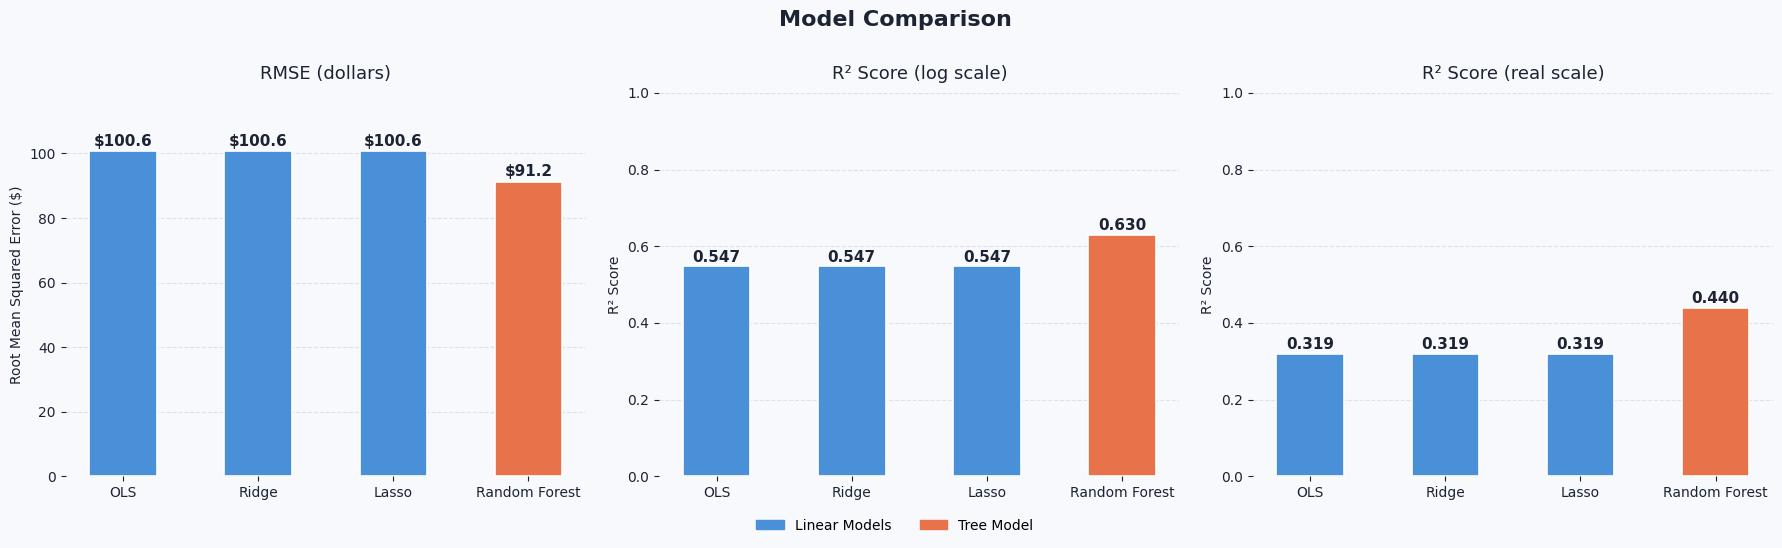

Salvato: slide_model_comparison.png


In [103]:
# ============================================================
# CELLA 1 — Model Comparison (RMSE & R²)
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
 
# --- Inserisci qui i tuoi valori reali ---
models    = ['OLS', 'Ridge', 'Lasso', 'Random Forest']
rmse      = [100.63, 100.64, 100.64, 91.23]   # in dollari
r2_log    = [0.5471,  0.5471,  0.5471,  0.630]   # R² su scala log (confrontabile con letteratura)
r2_dollars  = [0.3188, 0.3187, 0.3186, 0.440]
 
PALETTE = {
    'linear': '#4A90D9',
    'tree':   '#E8734A',
    'bg':     '#F7F9FC',
    'grid':   '#DDE3EC',
    'text':   '#1C2333',
}
bar_colors = [PALETTE['linear'], PALETTE['linear'], PALETTE['linear'], PALETTE['tree']]
 
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor=PALETTE['bg'])
fig.suptitle('Model Comparison', fontsize=16, fontweight='bold',
             color=PALETTE['text'], y=1.01)
 
# — RMSE —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
bars = ax1.bar(models, rmse, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, rmse):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f'${val:.1f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax1.set_title('RMSE (dollars)', fontsize=13, color=PALETTE['text'], pad=10)
ax1.set_ylabel('Root Mean Squared Error ($)', fontsize=10, color=PALETTE['text'])
ax1.set_ylim(0, max(rmse) * 1.18)
ax1.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top','right','left','bottom']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'])
 
# — R² log —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
bars2 = ax2.bar(models, r2_log, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars2, r2_log):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax2.set_title('R² Score (log scale)', fontsize=13, color=PALETTE['text'], pad=10)
ax2.set_ylabel('R² Score', fontsize=10, color=PALETTE['text'])
ax2.set_ylim(0, 1.0)
ax2.axhline(1.0, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax2.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top','right','left','bottom']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'])

# — R² real—
ax3 = axes[2]
ax3.set_facecolor(PALETTE['bg'])
bars3 = ax3.bar(models, r2_dollars, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars3, r2_dollars):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax3.set_title('R² Score (real scale)', fontsize=13, color=PALETTE['text'], pad=10)
ax3.set_ylabel('R² Score', fontsize=10, color=PALETTE['text'])
ax3.set_ylim(0, 1.0)
ax3.axhline(1.0, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax3.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax3.set_axisbelow(True)
ax3.spines[['top','right','left','bottom']].set_visible(False)
ax3.tick_params(colors=PALETTE['text'])
 
# Legenda
patch_l = mpatches.Patch(color=PALETTE['linear'], label='Linear Models')
patch_t = mpatches.Patch(color=PALETTE['tree'],   label='Tree Model')
fig.legend(handles=[patch_l, patch_t], loc='lower center', ncol=2,
           frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.06))
 
plt.tight_layout()
plt.savefig('slide_model_comparison.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_model_comparison.png")
 

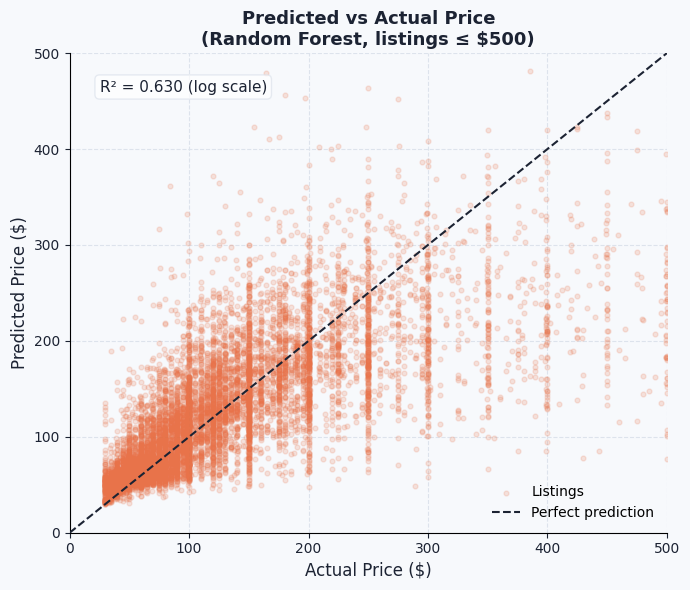

Salvato: slide_predicted_vs_actual.png


In [77]:
# ============================================================
# CELLA 2 — Predicted vs Actual (scatter)
# Richiede: y_test_tree, y_pred_log_tree (dalla cella TreePipeline)
# ============================================================
 
y_test_plot = np.expm1(y_test_tree)        # valori reali in $
y_pred_plot = np.expm1(y_pred_log_tree)    # predizioni in $
 
# Clip per leggibilità (rimuove outlier estremi dal grafico, NON dai dati)
clip = 500
mask = (y_test_plot <= clip) & (y_pred_plot <= clip)
yt, yp = y_test_plot[mask], y_pred_plot[mask]
 
fig, ax = plt.subplots(figsize=(7, 6), facecolor=PALETTE['bg'])
ax.set_facecolor(PALETTE['bg'])
 
ax.scatter(yt, yp, alpha=0.18, s=12, color=PALETTE['tree'], zorder=2, label='Listings')
ax.plot([0, clip], [0, clip], color='#1C2333', linewidth=1.5,
        linestyle='--', zorder=3, label='Perfect prediction')
 
ax.set_xlabel('Actual Price ($)', fontsize=12, color=PALETTE['text'])
ax.set_ylabel('Predicted Price ($)', fontsize=12, color=PALETTE['text'])
ax.set_title('Predicted vs Actual Price\n(Random Forest, listings ≤ $500)',
             fontsize=13, fontweight='bold', color=PALETTE['text'])
ax.set_xlim(0, clip); ax.set_ylim(0, clip)
ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(colors=PALETTE['text'])
ax.legend(frameon=False, fontsize=10)
 
# Annotazione R²
ax.text(0.05, 0.92, f'R² = 0.630 (log scale)', transform=ax.transAxes,
        fontsize=11, color=PALETTE['text'],
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor=PALETTE['grid']))
 
plt.tight_layout()
plt.savefig('slide_predicted_vs_actual.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_predicted_vs_actual.png")
 

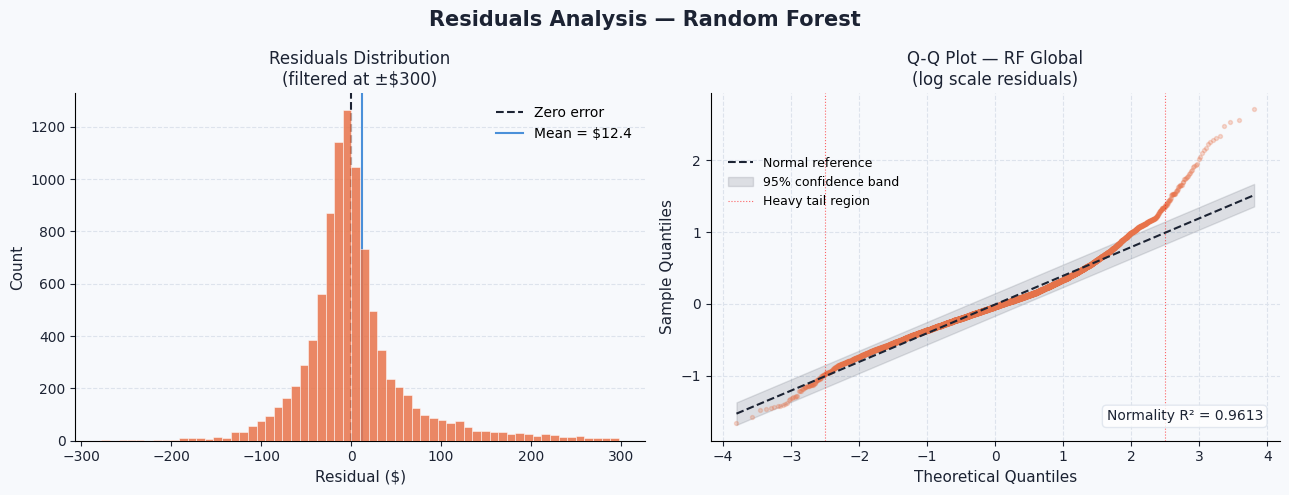

Salvato: slide_residuals.png


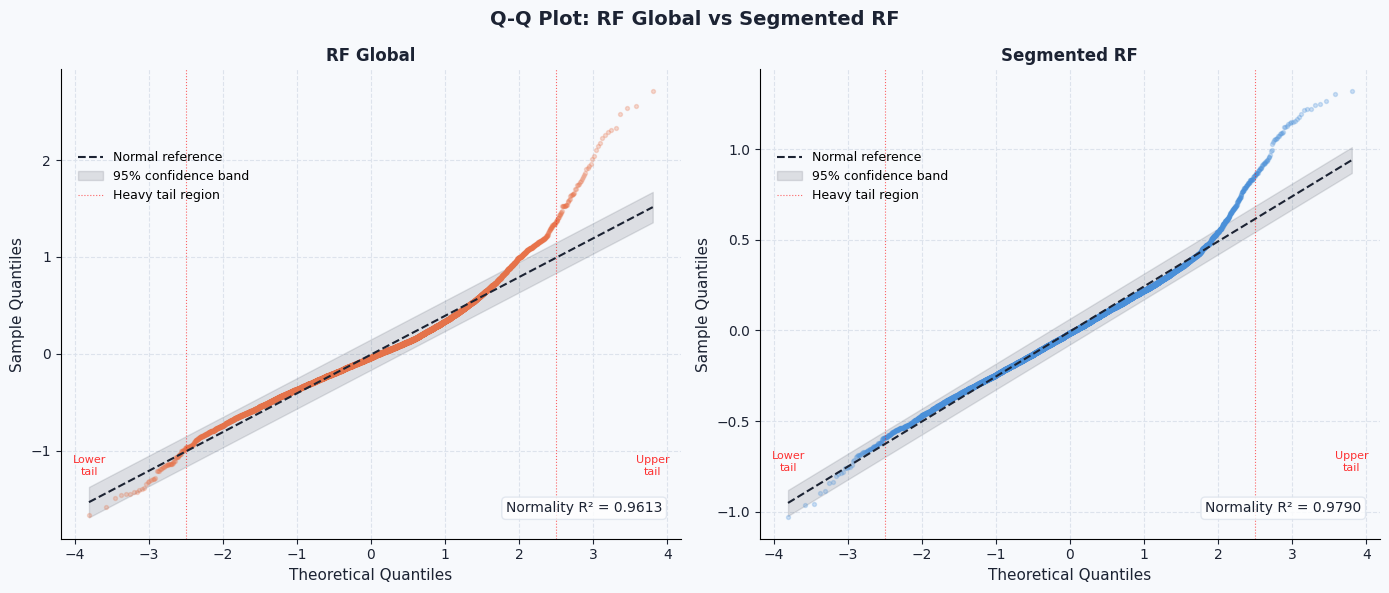

Salvato: slide_qqplot_comparison.png


In [78]:
# ============================================================
# CELLA 3 — Residuals Distribution + Q-Q Plot (RF Globale)
# ============================================================
from scipy import stats

residuals = y_test_plot - y_pred_plot  # residui in dollari

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=PALETTE['bg'])
fig.suptitle('Residuals Analysis — Random Forest', fontsize=15,
             fontweight='bold', color=PALETTE['text'])

# — Istogramma residui —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
residuals_filtered = residuals[(residuals >= -300) & (residuals <= 300)]
ax1.hist(residuals_filtered, bins=60, color=PALETTE['tree'],
         edgecolor='white', linewidth=0.4, zorder=3, alpha=0.85)
ax1.axvline(0, color='#1C2333', linewidth=1.5, linestyle='--', label='Zero error')
ax1.axvline(residuals.mean(), color=PALETTE['linear'], linewidth=1.5,
            linestyle='-', label=f'Mean = ${residuals.mean():.1f}')
ax1.set_xlabel('Residual ($)', fontsize=11, color=PALETTE['text'])
ax1.set_ylabel('Count', fontsize=11, color=PALETTE['text'])
ax1.set_title('Residuals Distribution\n(filtered at ±$300)', fontsize=12, color=PALETTE['text'])
ax1.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top', 'right']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'])
ax1.legend(frameon=False, fontsize=10)

# — Q-Q plot RF Globale —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
resid_log_global = np.array(y_test_tree) - y_pred_log_tree
(osm, osr), (slope, intercept, r) = stats.probplot(resid_log_global, dist="norm")
osm, osr = np.array(osm), np.array(osr)

ax2.scatter(osm, osr, color=PALETTE['tree'], alpha=0.25, s=8, zorder=2)
ax2.plot(osm, slope * osm + intercept,
         color='#1C2333', linewidth=1.5, linestyle='--',
         zorder=3, label='Normal reference')

upper = slope * osm + intercept + 1.96 * np.std(osr - (slope * osm + intercept))
lower = slope * osm + intercept - 1.96 * np.std(osr - (slope * osm + intercept))
ax2.fill_between(osm, lower, upper, alpha=0.12, color='#1C2333', label='95% confidence band')

ax2.axvline(-2.5, color='red', linewidth=0.8, linestyle=':', alpha=0.6, label='Heavy tail region')
ax2.axvline(2.5,  color='red', linewidth=0.8, linestyle=':', alpha=0.6)
# ax2.text(-3.8, osr.min() * 0.75, 'Lower\ntail', fontsize=8, color='red', alpha=0.8, ha='center')
# ax2.text(3.8,  osr.min() * 0.75, 'Upper\ntail', fontsize=8, color='red', alpha=0.8, ha='center')

ax2.text(0.97, 0.05, f'Normality R² = {r**2:.4f}',
         transform=ax2.transAxes, fontsize=10, color=PALETTE['text'],
         va='bottom', ha='right',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                   alpha=0.8, edgecolor=PALETTE['grid']))

ax2.set_xlabel('Theoretical Quantiles', fontsize=11, color=PALETTE['text'])
ax2.set_ylabel('Sample Quantiles', fontsize=11, color=PALETTE['text'])
ax2.set_title('Q-Q Plot — RF Global\n(log scale residuals)', fontsize=12, color=PALETTE['text'])
ax2.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top', 'right']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'])
ax2.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0.01, 0.85))

plt.tight_layout()
plt.savefig('slide_residuals.png', dpi=180, bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_residuals.png")


# ============================================================
# CELLA 3b — Q-Q Plot: RF Globale vs Segmented RF
# Richiede: y_pred_seg, y_test (dalla cella segmentazione)
# ============================================================

resid_segmented = np.array(y_test) - y_pred_seg

fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=PALETTE['bg'])
fig.suptitle('Q-Q Plot: RF Global vs Segmented RF',
             fontsize=14, fontweight='bold', color=PALETTE['text'])

for ax, resid, title, color in [
    (axes[0], resid_log_global, 'RF Global',    PALETTE['tree']),
    (axes[1], resid_segmented,  'Segmented RF', PALETTE['linear']),
]:
    ax.set_facecolor(PALETTE['bg'])
    (osm, osr), (slope, intercept, r) = stats.probplot(resid, dist="norm")
    osm, osr = np.array(osm), np.array(osr)

    ax.scatter(osm, osr, color=color, alpha=0.25, s=8, zorder=2)
    ax.plot(osm, slope * osm + intercept,
            color='#1C2333', linewidth=1.5, linestyle='--',
            zorder=3, label='Normal reference')

    upper = slope * osm + intercept + 1.96 * np.std(osr - (slope * osm + intercept))
    lower = slope * osm + intercept - 1.96 * np.std(osr - (slope * osm + intercept))
    ax.fill_between(osm, lower, upper, alpha=0.12,
                    color='#1C2333', label='95% confidence band')

    ax.axvline(-2.5, color='red', linewidth=0.8, linestyle=':', alpha=0.6, label='Heavy tail region')
    ax.axvline(2.5,  color='red', linewidth=0.8, linestyle=':', alpha=0.6)
    ax.text(-3.8, osr.min() * 0.75, 'Lower\ntail', fontsize=8, color='red', alpha=0.8, ha='center')
    ax.text(3.8,  osr.min() * 0.75, 'Upper\ntail', fontsize=8, color='red', alpha=0.8, ha='center')

    ax.text(0.97, 0.05, f'Normality R² = {r**2:.4f}',
            transform=ax.transAxes, fontsize=10, color=PALETTE['text'],
            va='bottom', ha='right',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.8, edgecolor=PALETTE['grid']))

    ax.set_xlabel('Theoretical Quantiles', fontsize=11, color=PALETTE['text'])
    ax.set_ylabel('Sample Quantiles', fontsize=11, color=PALETTE['text'])
    ax.set_title(title, fontsize=12, fontweight='bold', color=PALETTE['text'])
    ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors=PALETTE['text'])
    ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0.01, 0.85))

plt.tight_layout()
plt.savefig('slide_qqplot_comparison.png', dpi=180,
            bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_qqplot_comparison.png")

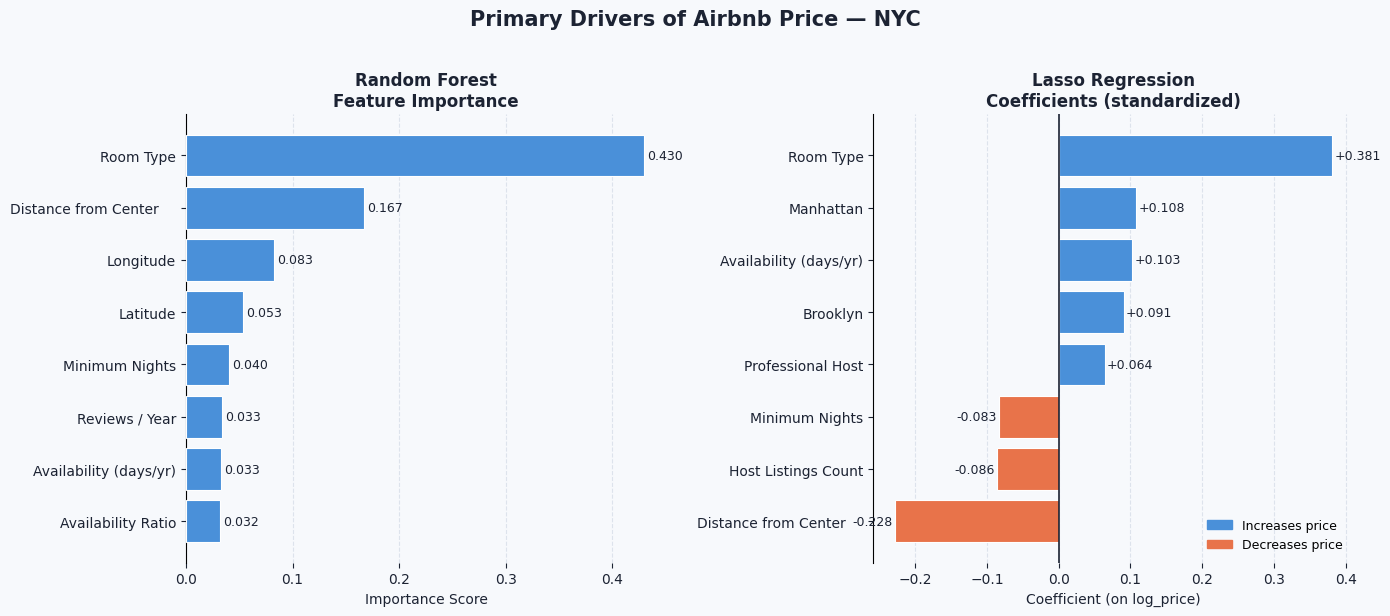

Salvato: slide_feature_importance.png


In [112]:
# ============================================================
# CELLA 4 — Feature Importance (slide version)
# Richiede: importanza_tree (dalla cella TreePipeline)
#           driver_attivi  (dalla cella LinearRegression/Lasso)
# ============================================================
 
# Rinominiamo le feature per le slide (più leggibili)
RENAME = {
    'room_type_ordinal':           'Room Type',
    'distance_from_center':        'Distance from Center    ',
    'latitude':                    'Latitude',
    'longitude':                   'Longitude',
    'minimum_nights':              'Minimum Nights',
    'reviews_per_year':            'Reviews / Year',
    'availability_365':            'Availability (days/yr)',
    'last_review_days_ago':        'Days Since Last Review',
    'number_of_reviews':           'Number of Reviews',
    'reviews_per_month':           'Reviews / Month',
    'calculated_host_listings_count': 'Host Listings Count',
    'host_is_professional':        'Professional Host',
    'availability_ratio':          'Availability Ratio',
    'neighbourhood_group_Manhattan': 'Manhattan',
    'neighbourhood_group_Brooklyn':  'Brooklyn',
    'neighbourhood_group_Queens':    'Queens',
    'neighbourhood_group_Staten Island': 'Staten Island',
    'neighbourhood_group_Bronx':     'Bronx',
}
 
# Top 8 RF
top_rf = importanza_tree.head(8).copy()
top_rf['Feature'] = top_rf['Feature'].map(lambda x: RENAME.get(x, x))
 
# Top 8 Lasso (per valore assoluto, già in driver_attivi)
top_lasso = driver_attivi.head(8).copy()
top_lasso['Feature'] = top_lasso['Feature'].map(lambda x: RENAME.get(x, x))
lasso_colors = [PALETTE['tree'] if v < 0 else PALETTE['linear']
                for v in top_lasso['Coefficiente'].sort_values()]
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=PALETTE['bg'])
fig.suptitle('Primary Drivers of Airbnb Price — NYC',
             fontsize=15, fontweight='bold', color=PALETTE['text'], y=1.02)

 
# — RF importance —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
sorted_rf = top_rf.sort_values('Importanza')
bars = ax1.barh(sorted_rf['Feature'], sorted_rf['Importanza'],
                color=PALETTE['linear'], edgecolor='white', linewidth=0.8, zorder=3)
for bar, val in zip(bars, sorted_rf['Importanza']):
    ax1.text(val + 0.003, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=9, color=PALETTE['text'])
ax1.set_title('Random Forest\nFeature Importance', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax1.set_xlabel('Importance Score', fontsize=10, color=PALETTE['text'])
ax1.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top','right','bottom']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'], labelsize=10)
 
# — Lasso coefficients —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
sorted_lasso = top_lasso.sort_values('Coefficiente')
ax2.barh(sorted_lasso['Feature'], sorted_lasso['Coefficiente'],
         color=lasso_colors, edgecolor='white', linewidth=0.8, zorder=3)
ax2.axvline(0, color='#1C2333', linewidth=1.2, zorder=4)
for i, (val, feat) in enumerate(zip(sorted_lasso['Coefficiente'], sorted_lasso['Feature'])):
    offset = 0.003 if val >= 0 else -0.003
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, i, f'{val:+.3f}', va='center',
             fontsize=9, color=PALETTE['text'], ha=ha)
ax2.set_title('Lasso Regression\nCoefficients (standardized)', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax2.set_xlabel('Coefficient (on log_price)', fontsize=10, color=PALETTE['text'])
ax2.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top','right','bottom']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'], labelsize=10)
 
pos_patch = mpatches.Patch(color=PALETTE['linear'], label='Increases price')
neg_patch = mpatches.Patch(color=PALETTE['tree'],   label='Decreases price')
ax2.legend(handles=[pos_patch, neg_patch], frameon=False, fontsize=9,
           loc='lower right')

 
plt.tight_layout()
plt.savefig('slide_feature_importance.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_feature_importance.png")

## Codice per trasformazione Yeo - Johnson sotto

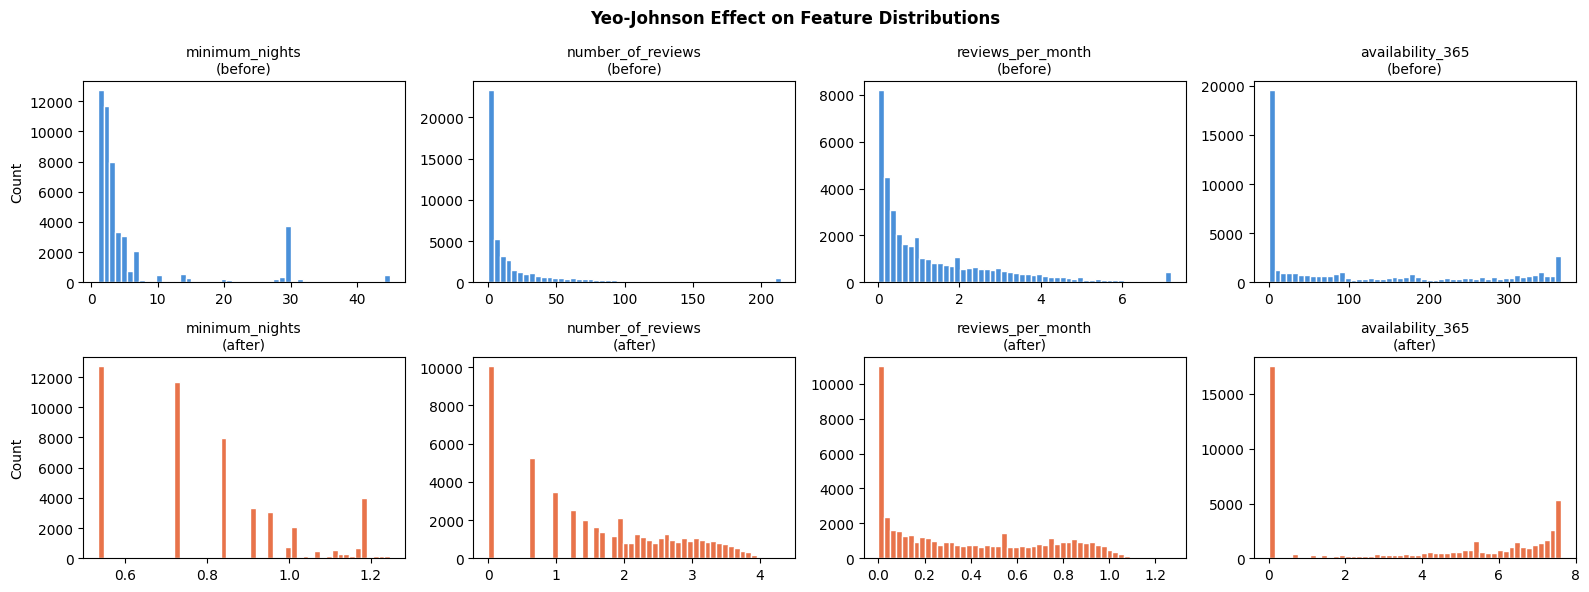

In [80]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import sys
import os
cartella_src = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))

if cartella_src not in sys.path:
    sys.path.insert(0, cartella_src)
# 1. Importiamo i moduli custom dai file fisici
from Preprocessor import FullPipeline
from Regression.LinearRegression import LinearRegression

# Pipeline SENZA Yeo-Johnson (dati grezzi dopo cleaning base)
raw = pd.read_csv('../Dataset/AB_NYC_2019.csv')

features_to_check = ['minimum_nights', 'number_of_reviews', 
                     'reviews_per_month', 'availability_365']

# Pipeline CON Yeo-Johnson
pipeline = FullPipeline('../Dataset/AB_NYC_2019.csv')
df_transformed = pipeline.transform()

fig, axes = plt.subplots(2, len(features_to_check), figsize=(16, 6))
fig.suptitle('Yeo-Johnson Effect on Feature Distributions', fontweight='bold')

for i, col in enumerate(features_to_check):
    # Prima
    if col in raw.columns:
        data_before = raw[col].dropna().clip(0, raw[col].quantile(0.99))
        axes[0, i].hist(data_before, bins=50, color='#4A90D9', edgecolor='white')
        axes[0, i].set_title(f'{col}\n(before)', fontsize=10)
        axes[0, i].set_ylabel('Count' if i == 0 else '')

    # Dopo
    if col in df_transformed.columns:
        axes[1, i].hist(df_transformed[col], bins=50, color='#E8734A', edgecolor='white')
        axes[1, i].set_title(f'{col}\n(after)', fontsize=10)
        axes[1, i].set_ylabel('Count' if i == 0 else '')

plt.tight_layout()
plt.show()

In [81]:
# Dati prima (grezzi)
raw_skew = raw[features_to_check].skew()

# Dati dopo
transformed_skew = df_transformed[features_to_check].skew()

comparison = pd.DataFrame({
    'Skewness Before': raw_skew.round(3),
    'Skewness After':  transformed_skew.round(3),
})
comparison['Improvement'] = (comparison['Skewness Before'].abs() - 
                              comparison['Skewness After'].abs()).round(3)

print(comparison)

                   Skewness Before  Skewness After  Improvement
minimum_nights              21.827           0.267       21.560
number_of_reviews            3.691           0.082        3.609
reviews_per_month            3.130           0.462        2.668
availability_365             0.763          -0.119        0.644


In [82]:
from MainRegression import Regression
from Preprocessor import FullPipeline

pipeline = FullPipeline('../Dataset/AB_NYC_2019.csv')
df = pipeline.transform()

reg = Regression(df, target_column='log_price')

metrics_ols   = reg.evaluate(model_type='linear', penalty=None)
metrics_ridge = reg.evaluate(model_type='linear', penalty='l2', alpha=1.0)
metrics_lasso = reg.evaluate(model_type='linear', penalty='l1', alpha=0.01)

print("\n--- Confronto con risultati precedenti ---")
print(f"OLS   RMSE: {metrics_ols['RMSE']:.2f}   (prima: 103.02)")
print(f"Ridge RMSE: {metrics_ridge['RMSE']:.2f}  (prima: 103.02)")
print(f"Lasso RMSE: {metrics_lasso['RMSE']:.2f}  (prima: 103.89)")

Dati divisi in training (39095 righe) e test (9774 righe).
Risultati 'linear': {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188}
Risultati 'linear': {'RMSE': np.float64(100.6296), 'MAE': 52.6411, 'R-squared': 0.3188}
Risultati 'linear': {'RMSE': np.float64(101.7799), 'MAE': 52.8954, 'R-squared': 0.3031}

--- Confronto con risultati precedenti ---
OLS   RMSE: 100.63   (prima: 103.02)
Ridge RMSE: 100.63  (prima: 103.02)
Lasso RMSE: 101.78  (prima: 103.89)


In [83]:
# ============================================================
# Yeo-Johnson sul TARGET — confronto con log_price
# ============================================================
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Ricarichiamo i dati con la FullPipeline attuale
# che già include Yeo-Johnson sulle feature e log_price come target
from Preprocessor import FullPipeline
from sklearn.model_selection import train_test_split

pipeline = FullPipeline('../Dataset/AB_NYC_2019.csv')
df = pipeline.transform()

# Usiamo il prezzo originale (prima della log transform)
# Ricostruiamo price da log_price
price_original = np.expm1(df['log_price'])
X = df.drop(columns=['log_price'])

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X, price_original, test_size=0.2, random_state=42
)

# --- APPROCCIO 1: target log_price (baseline attuale) ---
scaler_1 = StandardScaler()
X_train_s = scaler_1.fit_transform(X_train)
X_test_s  = scaler_1.transform(X_test)

y_train_log = np.log1p(y_train_raw)
y_test_log  = np.log1p(y_test_raw)

model_log = Ridge(alpha=1.0)
model_log.fit(X_train_s, y_train_log)
y_pred_log = model_log.predict(X_test_s)

# Invertiamo per metriche in dollari
y_pred_log_dollars = np.expm1(y_pred_log)
rmse_log = np.sqrt(mean_squared_error(y_test_raw, y_pred_log_dollars))
r2_log   = r2_score(y_test_log, y_pred_log)

print("--- Baseline: Log Transform on target ---")
print(f"  RMSE: ${rmse_log:.2f}")
print(f"  R² (transformed scale): {r2_log:.4f}")

# --- APPROCCIO 2: target Yeo-Johnson ---
scaler_2 = StandardScaler()
X_train_s2 = scaler_2.fit_transform(X_train)
X_test_s2  = scaler_2.transform(X_test)

# Fit del transformer SOLO sul training set
pt = PowerTransformer(method='yeo-johnson', standardize=False)
y_train_yj = pt.fit_transform(y_train_raw.values.reshape(-1, 1)).ravel()
y_test_yj  = pt.transform(y_test_raw.values.reshape(-1, 1)).ravel()

model_yj = Ridge(alpha=1.0)
model_yj.fit(X_train_s2, y_train_yj)
y_pred_yj = model_yj.predict(X_test_s2)

# Invertiamo con inverse_transform per tornare in dollari
y_pred_yj_dollars = pt.inverse_transform(y_pred_yj.reshape(-1, 1)).ravel()
rmse_yj = np.sqrt(mean_squared_error(y_test_raw, y_pred_yj_dollars))
r2_yj   = r2_score(y_test_yj, y_pred_yj)

print("\n--- Yeo-Johnson Transform on target ---")
print(f"  RMSE: ${rmse_yj:.2f}")
print(f"  R² (transformed scale): {r2_yj:.4f}")
print(f"  Lambda trovato: {pt.lambdas_[0]:.4f}")

# --- CONFRONTO ---
print("\n--- Confronto ---")
print(f"  RMSE miglioramento: ${rmse_log - rmse_yj:.2f}")
print(f"  Lambda Yeo-Johnson: {pt.lambdas_[0]:.4f}")
print(f"  (lambda ≈ 0 → simile al log; lambda = 1 → nessuna trasformazione)")

--- Baseline: Log Transform on target ---
  RMSE: $100.63
  R² (transformed scale): 0.5471

--- Yeo-Johnson Transform on target ---
  RMSE: $101.27
  R² (transformed scale): 0.5694
  Lambda trovato: -0.2328

--- Confronto ---
  RMSE miglioramento: $-0.64
  Lambda Yeo-Johnson: -0.2328
  (lambda ≈ 0 → simile al log; lambda = 1 → nessuna trasformazione)


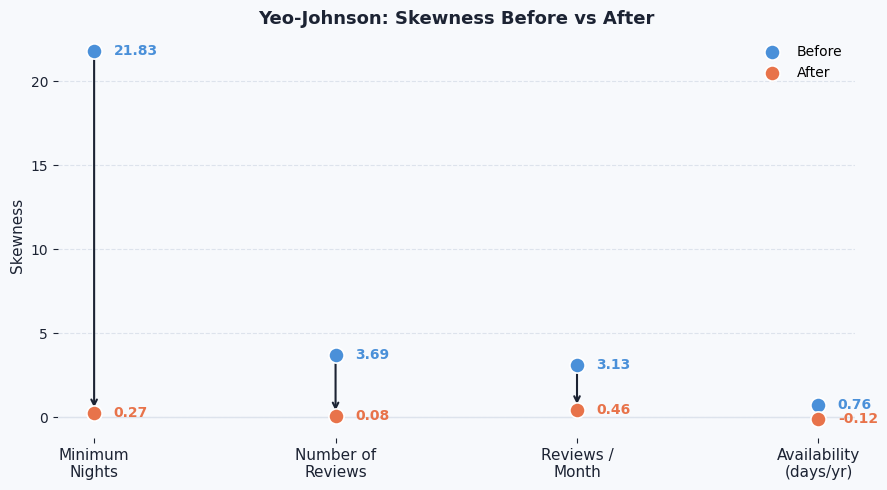

In [84]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor=PALETTE['bg'])
ax.set_facecolor(PALETTE['bg'])

features_short = ['Minimum\nNights', 'Number of\nReviews',
                  'Reviews /\nMonth', 'Availability\n(days/yr)']
before = [21.827, 3.691, 3.130, 0.763]
after  = [0.267,  0.082, 0.462, -0.119]
x = np.arange(len(features_short))

# Frecce da "before" a "after"
for i, (b, a) in enumerate(zip(before, after)):
    ax.annotate('', xy=(i, a), xytext=(i, b),
                arrowprops=dict(arrowstyle='->', color='#1C2333',
                                lw=1.5, shrinkA=4, shrinkB=4))

# Punti before e after
ax.scatter(x, before, s=120, color=PALETTE['linear'],
           zorder=4, label='Before', edgecolors='white', linewidth=1.2)
ax.scatter(x, after,  s=120, color=PALETTE['tree'],
           zorder=4, label='After',  edgecolors='white', linewidth=1.2)

# Annotazioni valori
for i, (b, a) in enumerate(zip(before, after)):
    ax.text(i + 0.08, b, f'{b:.2f}', va='center', fontsize=10,
            color=PALETTE['linear'], fontweight='bold')
    ax.text(i + 0.08, a, f'{a:.2f}', va='center', fontsize=10,
            color=PALETTE['tree'], fontweight='bold')

ax.axhline(0, color=PALETTE['grid'], linewidth=1.0, linestyle='-')
ax.set_xticks(x)
ax.set_xticklabels(features_short, fontsize=11, color=PALETTE['text'])
ax.set_ylabel('Skewness', fontsize=11, color=PALETTE['text'])
ax.set_title('Yeo-Johnson: Skewness Before vs After',
             fontsize=13, fontweight='bold', color=PALETTE['text'])
ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(colors=PALETTE['text'])
ax.legend(frameon=False, fontsize=10, loc='upper right')

plt.tight_layout()
plt.savefig('slide_yeo_johnson_clean.png', dpi=180,
            bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()

Fine codice trasformazione

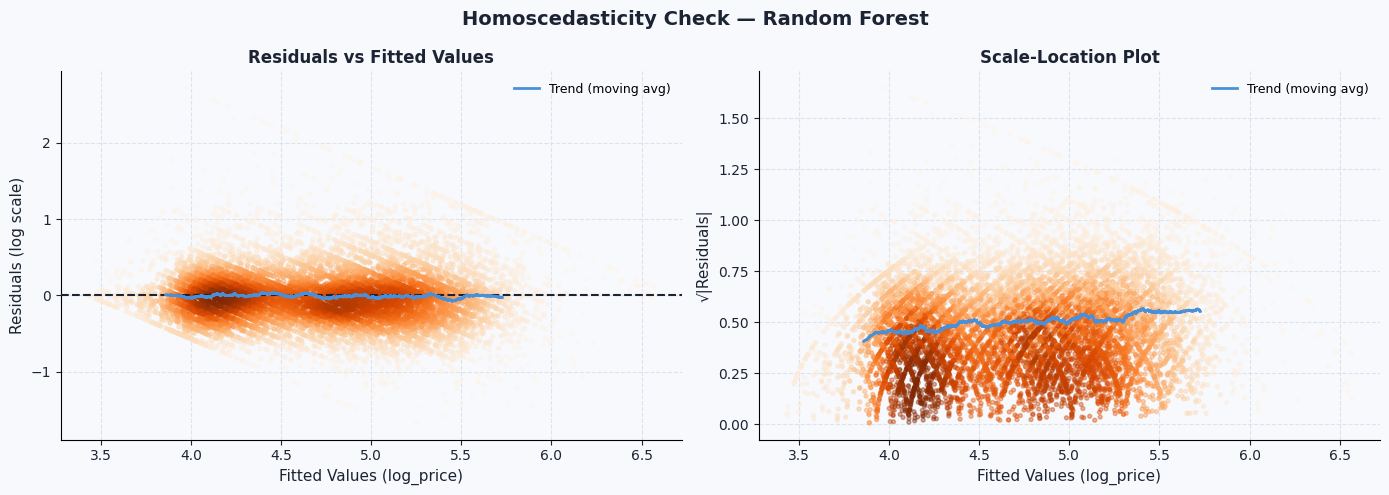

Salvato: slide_homoscedasticity.png


In [85]:
# ============================================================
# Omoschedasticità — Residuals vs Fitted Values
# Richiede: y_pred_log_tree, y_test_tree (dalla cella TreePipeline)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

PALETTE = {
    'tree': '#E8734A',
    'bg':   '#F7F9FC',
    'grid': '#DDE3EC',
    'text': '#1C2333',
}

# Lavoriamo su scala logaritmica: è lì che il modello opera
fitted   = y_pred_log_tree                        # valori predetti (log scale)
residuals_log = np.array(y_test_tree) - fitted    # residui (log scale)

# Densità per colorare i punti (zone più dense = colore più scuro)
xy = np.vstack([fitted, residuals_log])
density = gaussian_kde(xy)(xy)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=PALETTE['bg'])
fig.suptitle('Homoscedasticity Check — Random Forest',
             fontsize=14, fontweight='bold', color=PALETTE['text'])

# --- PLOT 1: Residuals vs Fitted ---
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
sc = ax1.scatter(fitted, residuals_log, c=density, cmap='Oranges',
                 alpha=0.4, s=8, zorder=2)
ax1.axhline(0, color='#1C2333', linewidth=1.5, linestyle='--', zorder=3)

# Linea di tendenza (LOWESS semplificato con media mobile)
sorted_idx = np.argsort(fitted)
fitted_sorted = fitted[sorted_idx]
resid_sorted  = residuals_log[sorted_idx]
window = len(fitted_sorted) // 20
trend = np.convolve(resid_sorted, np.ones(window)/window, mode='valid')
ax1.plot(fitted_sorted[window//2: window//2 + len(trend)], trend,
         color='#4A90D9', linewidth=2, zorder=4, label='Trend (moving avg)')

ax1.set_xlabel('Fitted Values (log_price)', fontsize=11, color=PALETTE['text'])
ax1.set_ylabel('Residuals (log scale)', fontsize=11, color=PALETTE['text'])
ax1.set_title('Residuals vs Fitted Values', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax1.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top', 'right']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'])
ax1.legend(frameon=False, fontsize=9)

# --- PLOT 2: Scale-Location (sqrt residui assoluti vs fitted) ---
# Rende più visibile l'aumento della varianza
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
sqrt_abs_resid = np.sqrt(np.abs(residuals_log))
sc2 = ax2.scatter(fitted, sqrt_abs_resid, c=density, cmap='Oranges',
                  alpha=0.4, s=8, zorder=2)

sqrt_sorted = sqrt_abs_resid[sorted_idx]
trend2 = np.convolve(sqrt_sorted, np.ones(window)/window, mode='valid')
ax2.plot(fitted_sorted[window//2: window//2 + len(trend2)], trend2,
         color='#4A90D9', linewidth=2, zorder=4, label='Trend (moving avg)')

ax2.set_xlabel('Fitted Values (log_price)', fontsize=11, color=PALETTE['text'])
ax2.set_ylabel('√|Residuals|', fontsize=11, color=PALETTE['text'])
ax2.set_title('Scale-Location Plot', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax2.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top', 'right']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'])
ax2.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig('slide_homoscedasticity.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_homoscedasticity.png")

In [86]:
!pip install statsmodels


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
# ============================================================
# STEP 1 — Breusch-Pagan Test (quantifica l'eteroschedasticità)
# ============================================================
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant
import numpy as np
import pandas as pd

# Usiamo i residui del modello lineare (OLS) già addestrato
# Richiede: X_train_scaled, y_train, X_test_scaled, y_test (dalla cella FullPipeline)

from sklearn.linear_model import LinearRegression as SklearnOLS
from sklearn.preprocessing import StandardScaler

scaler_bp = StandardScaler()
X_train_bp = scaler_bp.fit_transform(X_train)
X_test_bp  = scaler_bp.transform(X_test)

ols_bp = SklearnOLS()
ols_bp.fit(X_train_bp, y_train)
y_pred_bp = ols_bp.predict(X_test_bp)
residuals_bp = np.array(y_test) - y_pred_bp

# Il test richiede i regressori del test set con costante
X_test_const = add_constant(X_test_bp)
bp_test = het_breuschpagan(residuals_bp, X_test_const)

labels = ['LM Statistic', 'LM p-value', 'F Statistic', 'F p-value']
print("--- Breusch-Pagan Test (BEFORE) ---")
for label, val in zip(labels, bp_test):
    print(f"  {label}: {val:.4f}")
print()
print("Interpretazione: p-value < 0.05 → eteroschedasticità significativa")

--- Breusch-Pagan Test (BEFORE) ---
  LM Statistic: 258.2653
  LM p-value: 0.0000
  F Statistic: 16.5508
  F p-value: 0.0000

Interpretazione: p-value < 0.05 → eteroschedasticità significativa


In [88]:
# ============================================================
# STEP 2 — Weighted Least Squares (WLS)
# I pesi sono inversamente proporzionali ai valori predetti
# (chi ha prezzo alto ha varianza alta → peso basso)
# ============================================================
from sklearn.linear_model import LinearRegression as SklearnOLS

# 1. Primo fit OLS per stimare i fitted values sul training set
scaler_wls = StandardScaler()
X_train_wls = scaler_wls.fit_transform(X_train)
X_test_wls  = scaler_wls.transform(X_test)

first_ols = SklearnOLS()
first_ols.fit(X_train_wls, y_train)
y_fitted_train = first_ols.predict(X_train_wls)

# 2. Calcoliamo i pesi: 1 / fitted_value^2
# np.maximum evita divisioni per zero o pesi esplosivi su valori molto bassi
weights = 1.0 / np.maximum(np.exp(y_fitted_train) ** 2, 1e-6)
weights = weights / weights.mean()  # normalizziamo per stabilità numerica

# 3. WLS: passiamo i pesi come sample_weight
wls_model = SklearnOLS()
wls_model.fit(X_train_wls, y_train, sample_weight=weights)

y_pred_wls = wls_model.predict(X_test_wls)
residuals_wls = np.array(y_test) - y_pred_wls

# Metriche
from sklearn.metrics import mean_squared_error, r2_score
rmse_wls = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(y_pred_wls)))
r2_wls   = r2_score(y_test, y_pred_wls)

print("--- WLS Results ---")
print(f"  RMSE: ${rmse_wls:.2f}  (OLS baseline: $100.63)")
print(f"  R²:   {r2_wls:.4f}   (OLS baseline:  0.319)")

# Breusch-Pagan DOPO WLS
X_test_const = add_constant(X_test_wls)
bp_after_wls = het_breuschpagan(residuals_wls, X_test_const)
print("\n--- Breusch-Pagan Test (AFTER WLS) ---")
for label, val in zip(labels, bp_after_wls):
    print(f"  {label}: {val:.4f}")

--- WLS Results ---
  RMSE: $105.30  (OLS baseline: $100.63)
  R²:   0.5219   (OLS baseline:  0.319)

--- Breusch-Pagan Test (AFTER WLS) ---
  LM Statistic: 299.6184
  LM p-value: 0.0000
  F Statistic: 19.2847
  F p-value: 0.0000


In [89]:
# ============================================================
# STEP 3 — HuberRegressor (regressione robusta)
# Downpesa automaticamente gli outlier del segmento luxury
# epsilon controlla la soglia oltre cui un punto è considerato outlier
# ============================================================
from sklearn.linear_model import HuberRegressor

scaler_hub = StandardScaler()
X_train_hub = scaler_hub.fit_transform(X_train)
X_test_hub  = scaler_hub.transform(X_test)

# epsilon=1.35 è il valore standard (95% efficienza su dati normali)
huber = HuberRegressor(epsilon=1.35, max_iter=200)
huber.fit(X_train_hub, y_train)

y_pred_hub    = huber.predict(X_test_hub)
residuals_hub = np.array(y_test) - y_pred_hub

rmse_hub = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(y_pred_hub)))
r2_hub   = r2_score(y_test, y_pred_hub)

print("--- HuberRegressor Results ---")
print(f"  RMSE: ${rmse_hub:.2f}")
print(f"  R²:   {r2_hub:.4f}")

bp_huber = het_breuschpagan(residuals_hub, add_constant(X_test_hub))
print("\n--- Breusch-Pagan Test (AFTER Huber) ---")
for label, val in zip(labels, bp_huber):
    print(f"  {label}: {val:.4f}")

--- HuberRegressor Results ---
  RMSE: $102.49
  R²:   0.5406

--- Breusch-Pagan Test (AFTER Huber) ---
  LM Statistic: 271.1439
  LM p-value: 0.0000
  F Statistic: 17.3997
  F p-value: 0.0000


In [90]:
# ============================================================
# STEP 4 — Price Segmentation (approccio più efficace)
# Modelli separati per fascia di prezzo
# Soglie: budget < $75, mid $75-$175, luxury > $175
# ============================================================
from Regression.TreeRegression import TreeRegression

# Le soglie sono su log_price
budget_threshold = np.log1p(75)
luxury_threshold = np.log1p(175)

# Split del training set per fascia
mask_budget_train = y_train <= budget_threshold
mask_mid_train    = (y_train > budget_threshold) & (y_train <= luxury_threshold)
mask_luxury_train = y_train > luxury_threshold

# Split del test set per fascia
mask_budget_test = y_test <= budget_threshold
mask_mid_test    = (y_test > budget_threshold) & (y_test <= luxury_threshold)
mask_luxury_test = y_test > luxury_threshold

print("--- Distribuzione per fascia ---")
print(f"  Budget  (≤$75):   {mask_budget_train.sum()} train, {mask_budget_test.sum()} test")
print(f"  Mid ($75-$175):   {mask_mid_train.sum()} train,  {mask_mid_test.sum()} test")
print(f"  Luxury  (>$175):  {mask_luxury_train.sum()} train, {mask_luxury_test.sum()} test")

# Addestriamo un RF per ogni fascia
models_seg = {}
y_pred_seg = np.zeros(len(y_test))

for name, train_mask, test_mask in [
    ('budget',  mask_budget_train, mask_budget_test),
    ('mid',     mask_mid_train,    mask_mid_test),
    ('luxury',  mask_luxury_train, mask_luxury_test),
]:
    if train_mask.sum() < 50:
        print(f"  SKIP {name}: troppo pochi campioni")
        continue

    model = TreeRegression(n_estimators=100, max_depth=20)
    model.fit(X_train[train_mask], y_train[train_mask])
    
    if test_mask.sum() > 0:
        y_pred_seg[test_mask] = model.predict(X_test[test_mask])
    
    models_seg[name] = model
    
    # RMSE per fascia
    rmse_seg = np.sqrt(mean_squared_error(
        np.expm1(y_test[test_mask]),
        np.expm1(y_pred_seg[test_mask])
    ))
    r2_seg = r2_score(y_test[test_mask], y_pred_seg[test_mask])
    print(f"\n  [{name.upper()}] RMSE: ${rmse_seg:.2f}  R²: {r2_seg:.4f}")

# Metrica globale del modello segmentato
rmse_global = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(y_pred_seg)))
r2_global   = r2_score(y_test, y_pred_seg)
residuals_seg = np.array(y_test) - y_pred_seg

print(f"\n--- Segmented RF — Global Results ---")
print(f"  RMSE: ${rmse_global:.2f}  (RF baseline: $91.20)")
print(f"  R²:   {r2_global:.4f}   (RF baseline:  0.630)")

--- Distribuzione per fascia ---
  Budget  (≤$75):   12149 train, 3083 test
  Mid ($75-$175):   17207 train,  4257 test
  Luxury  (>$175):  9739 train, 2434 test

  [BUDGET] RMSE: $11.19  R²: 0.2831

  [MID] RMSE: $24.09  R²: 0.2670

  [LUXURY] RMSE: $135.90  R²: 0.1645

--- Segmented RF — Global Results ---
  RMSE: $69.94  (RF baseline: $91.20)
  R²:   0.8602   (RF baseline:  0.630)


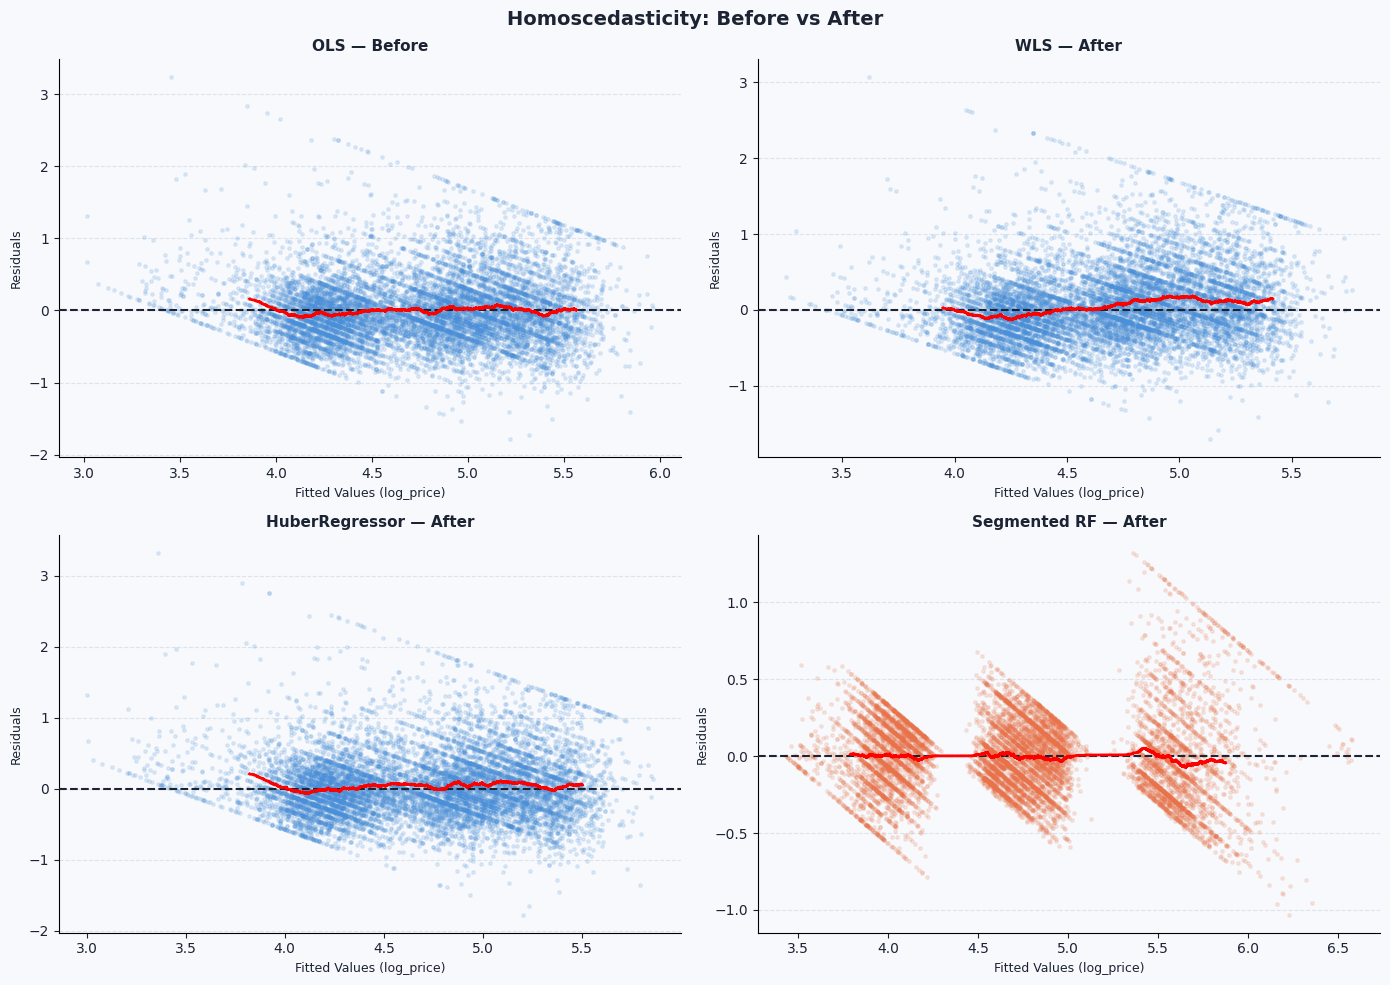

Salvato: slide_homoscedasticity_comparison.png


In [91]:
# ============================================================
# STEP 5 — Confronto omoschedasticità: Before vs After
# ============================================================
import matplotlib.pyplot as plt

PALETTE = {'tree': '#E8734A', 'linear': '#4A90D9',
           'bg': '#F7F9FC', 'grid': '#DDE3EC', 'text': '#1C2333'}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor=PALETTE['bg'])
fig.suptitle('Homoscedasticity: Before vs After',
             fontsize=14, fontweight='bold', color=PALETTE['text'])

configs = [
    (axes[0,0], y_pred_bp,   residuals_bp,   'OLS — Before',          PALETTE['linear']),
    (axes[0,1], y_pred_wls,  residuals_wls,  'WLS — After',           PALETTE['linear']),
    (axes[1,0], y_pred_hub,  residuals_hub,  'HuberRegressor — After',PALETTE['linear']),
    (axes[1,1], y_pred_seg,  residuals_seg,  'Segmented RF — After',  PALETTE['tree']),
]

for ax, fitted, resid, title, color in configs:
    ax.set_facecolor(PALETTE['bg'])
    ax.scatter(fitted, resid, alpha=0.15, s=6, color=color, zorder=2)
    ax.axhline(0, color='#1C2333', linewidth=1.5, linestyle='--', zorder=3)

    # Trend line
    sorted_idx  = np.argsort(fitted)
    window      = len(fitted) // 20
    trend       = np.convolve(resid[sorted_idx], np.ones(window)/window, mode='valid')
    ax.plot(fitted[sorted_idx][window//2: window//2 + len(trend)],
            trend, color='red', linewidth=2, zorder=4)

    ax.set_title(title, fontsize=11, fontweight='bold', color=PALETTE['text'])
    ax.set_xlabel('Fitted Values (log_price)', fontsize=9, color=PALETTE['text'])
    ax.set_ylabel('Residuals', fontsize=9, color=PALETTE['text'])
    ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(colors=PALETTE['text'])

plt.tight_layout()
plt.savefig('slide_homoscedasticity_comparison.png', dpi=180,
            bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_homoscedasticity_comparison.png")

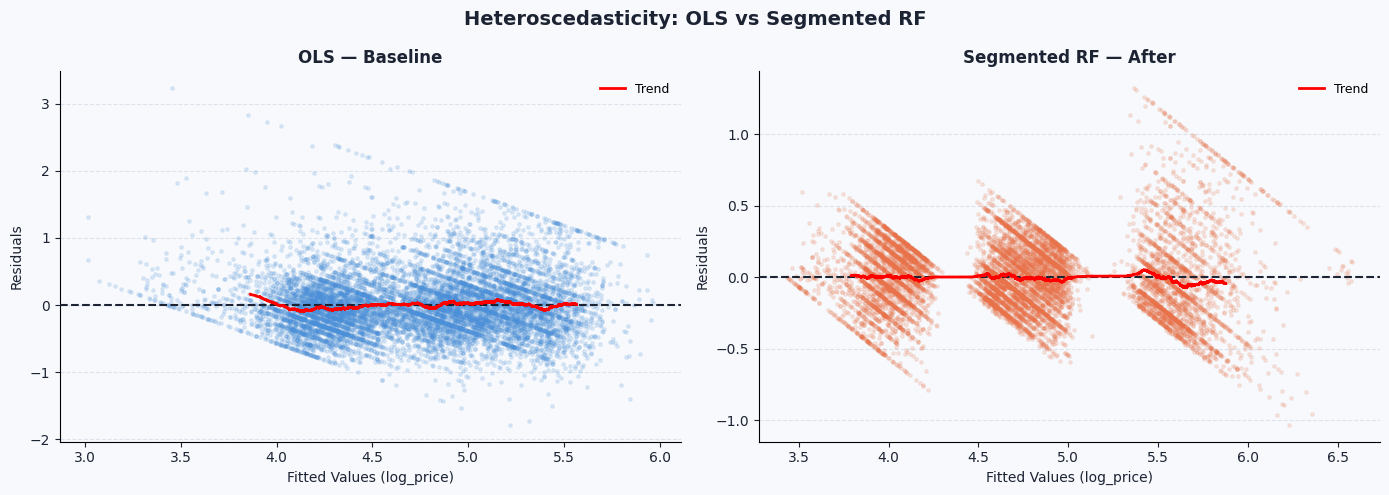

In [92]:
# Confronto pulito: OLS vs Segmented RF
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=PALETTE['bg'])
fig.suptitle('Heteroscedasticity: OLS vs Segmented RF',
             fontsize=14, fontweight='bold', color=PALETTE['text'])

configs = [
    (axes[0], y_pred_bp,  residuals_bp,  'OLS — Baseline',       '#4A90D9'),
    (axes[1], y_pred_seg, residuals_seg, 'Segmented RF — After', '#E8734A'),
]

for ax, fitted, resid, title, color in configs:
    ax.set_facecolor(PALETTE['bg'])
    ax.scatter(fitted, resid, alpha=0.15, s=6, color=color, zorder=2)
    ax.axhline(0, color='#1C2333', linewidth=1.5, linestyle='--', zorder=3)

    sorted_idx = np.argsort(fitted)
    window     = len(fitted) // 20
    trend      = np.convolve(resid[sorted_idx],
                             np.ones(window)/window, mode='valid')
    ax.plot(fitted[sorted_idx][window//2: window//2 + len(trend)],
            trend, color='red', linewidth=2, zorder=4, label='Trend')

    ax.set_title(title, fontsize=12, fontweight='bold', color=PALETTE['text'])
    ax.set_xlabel('Fitted Values (log_price)', fontsize=10, color=PALETTE['text'])
    ax.set_ylabel('Residuals', fontsize=10, color=PALETTE['text'])
    ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors=PALETTE['text'])
    ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig('slide_homoscedasticity_clean.png', dpi=180,
            bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()

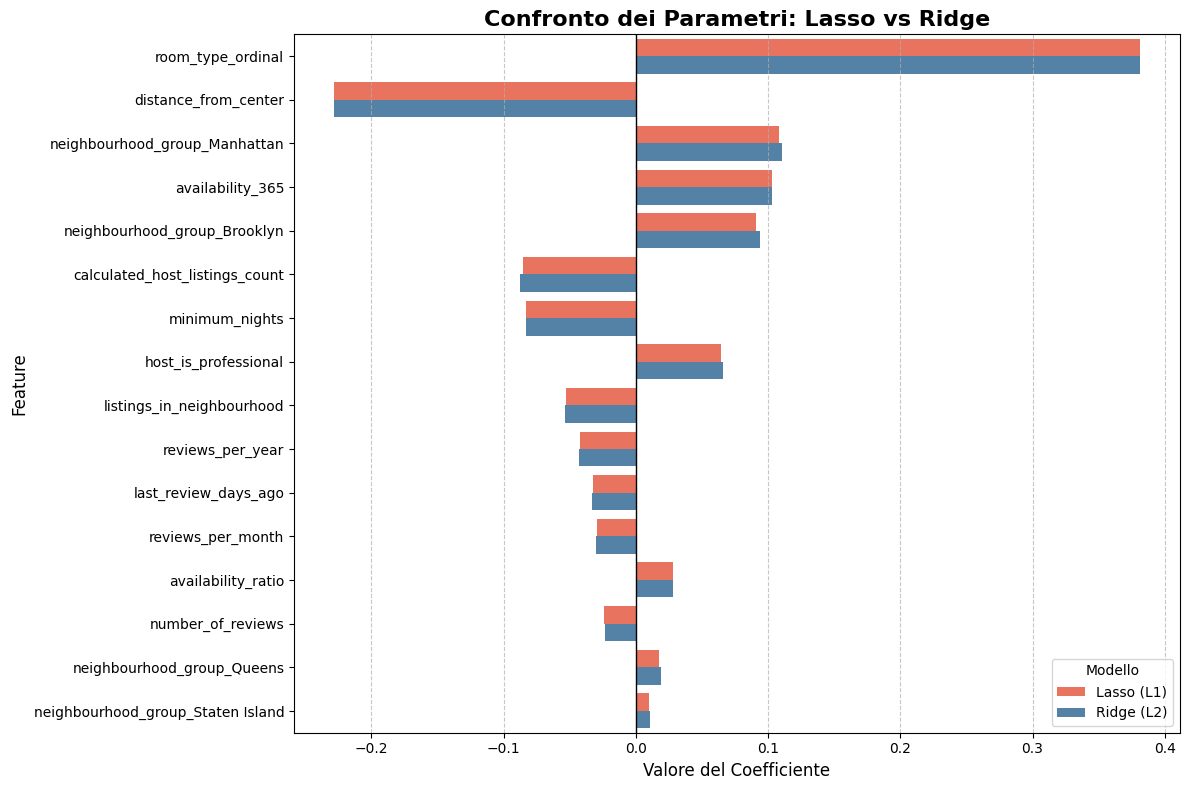

In [108]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importiamo la tua classe (assicurati che la cella dei percorsi sia già stata eseguita)
from Regression.LinearRegression import LinearRegression

# 1. Addestramento del modello Lasso
# Il parametro penalty='l1' attiva Lasso, che tende ad azzerare alcuni coefficienti (feature selection)
lasso_model = LinearRegression(penalty='l1', alpha=0.0001)
lasso_model.fit(X_train_scaled, y_train)

# 2. Addestramento del modello Ridge
# Il parametro penalty='l2' attiva Ridge, che riduce i coefficienti proporzionalmente ma non li azzera
ridge_model = LinearRegression(penalty='l2', alpha=16.76833)
ridge_model.fit(X_train_scaled, y_train)

# 3. Creazione di un DataFrame aggregato utilizzando la tua nuova proprietà 'coefficients'
df_coefs = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Lasso (L1)': lasso_model.coefficients,
    'Ridge (L2)': ridge_model.coefficients
})

# 4. Ordinamento delle feature per impatto (valore assoluto) per rendere il grafico leggibile
df_coefs['Impatto_Medio'] = (df_coefs['Lasso (L1)'].abs() + df_coefs['Ridge (L2)'].abs()) / 2
df_coefs = df_coefs.sort_values(by='Impatto_Medio', ascending=False).drop(columns=['Impatto_Medio'])

# 5. Melt del DataFrame (formato "lungo" richiesto da seaborn per il raggruppamento)
df_melted = df_coefs.melt(id_vars='Feature', var_name='Modello', value_name='Coefficiente')

# 6. Creazione della visualizzazione
plt.figure(figsize=(12, 8))
sns.barplot(data=df_melted, y='Feature', x='Coefficiente', hue='Modello', palette=['tomato', 'steelblue'])

# Personalizzazione estetica del grafico
plt.title('Confronto dei Parametri: Lasso vs Ridge', fontsize=16, fontweight='bold')
plt.xlabel('Valore del Coefficiente', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.axvline(x=0, color='black', linestyle='-', linewidth=1) # Linea dello zero per riferimento
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(title='Modello', loc='lower right')

plt.tight_layout()
plt.show()

Risultati 'linear': {'RMSE': np.float64(100.6292), 'MAE': 52.6412, 'R-squared': 0.3188, 'R-squared (log)': 0.5471}
Risultati 'linear': {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187, 'R-squared (log)': 0.5471}
Feature Selection completata: mantenute 16 variabili su 16.
Risultati 'linear': {'RMSE': np.float64(100.6408), 'MAE': 52.6403, 'R-squared': 0.3186, 'R-squared (log)': 0.5471}


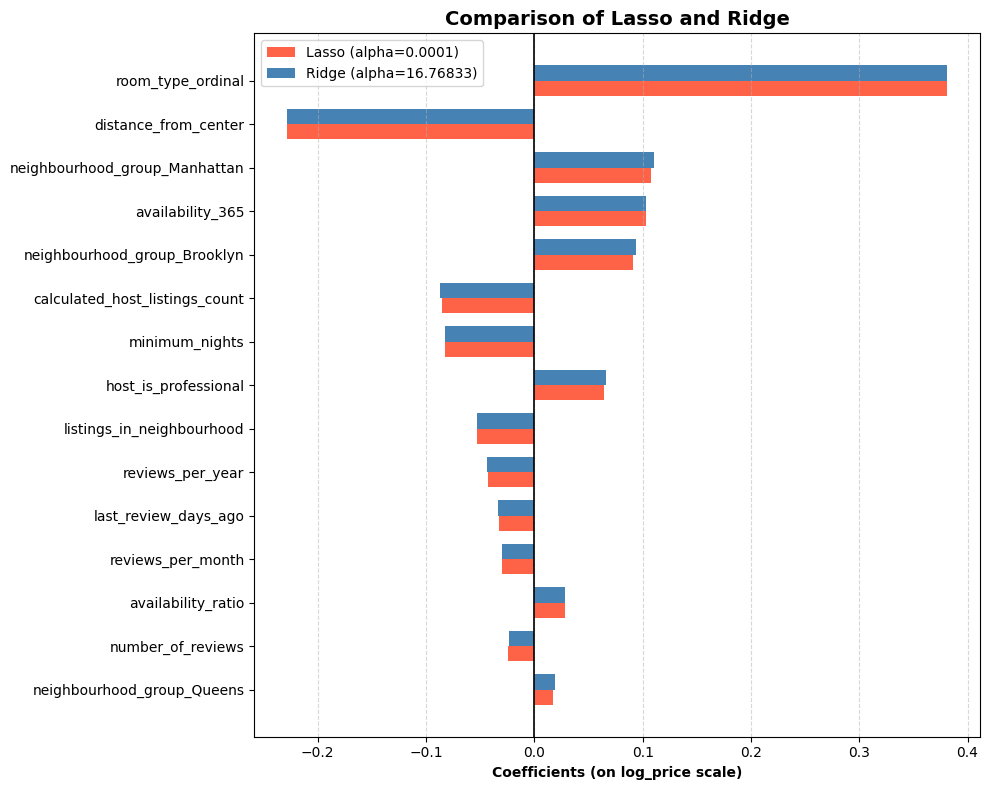

In [110]:
from MainRegression import Regression

# Valutazione singola dei modelli come hai già fatto
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=16.76833)
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.0001, use_feature_selection=True)

# Visualizzazione comparativa unificata
reg_linear.plot_lasso_ridge_comparison(alpha_lasso=0.0001, alpha_ridge=16.76833, top_n=15)


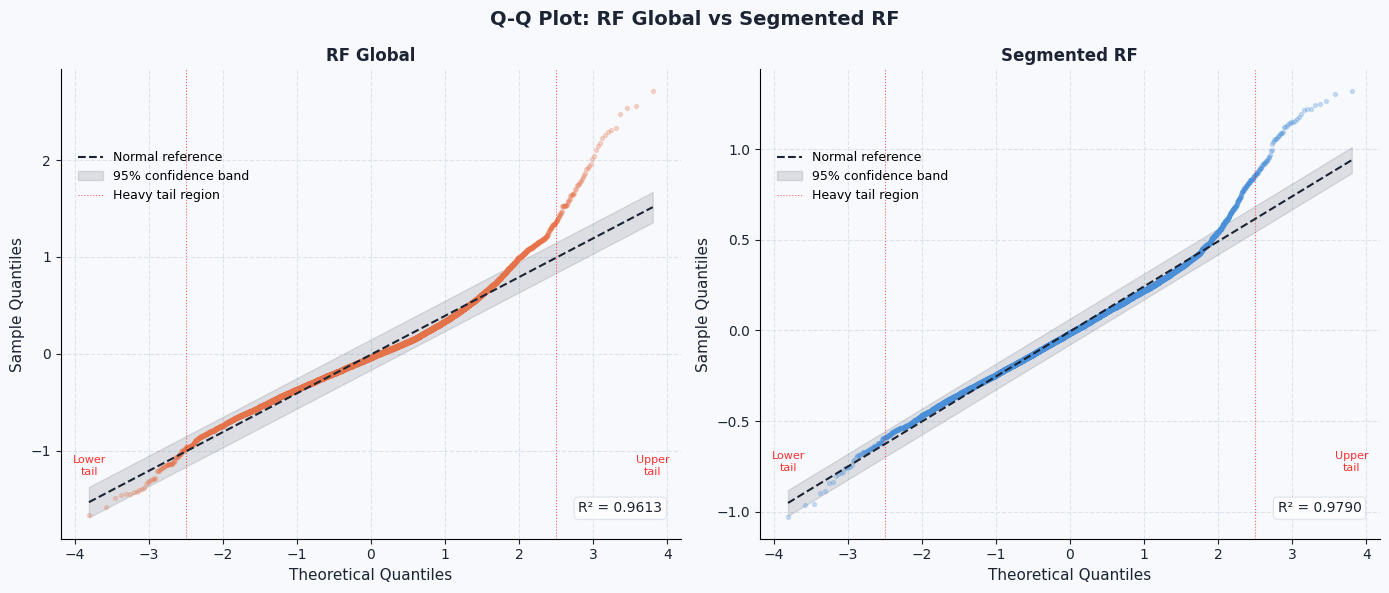

In [95]:
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

PALETTE = {
    'tree': '#E8734A', 'linear': '#4A90D9',
    'bg': '#F7F9FC', 'grid': '#DDE3EC', 'text': '#1C2333',
}

# Residui RF globale (già disponibile)
resid_global = np.array(y_test_tree) - y_pred_log_tree

# Residui Segmented RF
resid_segmented = np.array(y_test) - y_pred_seg

fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=PALETTE['bg'])
fig.suptitle('Q-Q Plot: RF Global vs Segmented RF',
             fontsize=14, fontweight='bold', color=PALETTE['text'])

tail_threshold = 2.5

for ax, resid, title, color in [
    (axes[0], resid_global,    'RF Global',    PALETTE['tree']),
    (axes[1], resid_segmented, 'Segmented RF', PALETTE['linear']),
]:
    ax.set_facecolor(PALETTE['bg'])

    # Q-Q plot base
    (osm, osr), (slope, intercept, r) = stats.probplot(resid, dist="norm")
    osm, osr = np.array(osm), np.array(osr)

    # Scatter dei quantili campionari vs teorici
    ax.scatter(osm, osr, color=color, alpha=0.25, s=8, zorder=2)

    # Linea di riferimento normale
    ax.plot(osm, slope * osm + intercept,
            color='#1C2333', linewidth=1.5, linestyle='--',
            zorder=3, label='Normal reference')

    # Bande di confidenza al 95%
    upper = slope * osm + intercept + 1.96 * np.std(osr - (slope * osm + intercept))
    lower = slope * osm + intercept - 1.96 * np.std(osr - (slope * osm + intercept))
    ax.fill_between(osm, lower, upper, alpha=0.12,
                    color='#1C2333', label='95% confidence band')

    # Linee di soglia per le code pesanti
    ax.axvline(-tail_threshold, color='red', linewidth=0.8,
               linestyle=':', alpha=0.6, label='Heavy tail region')
    ax.axvline(tail_threshold, color='red', linewidth=0.8,
               linestyle=':', alpha=0.6)

    # Annotazioni code: posizionate FUORI dalla zona densa
    ax.text(-3.8, osr.min() * 0.75, 'Lower\ntail',
            fontsize=8, color='red', alpha=0.8, ha='center')
    ax.text(3.8, osr.min() * 0.75, 'Upper\ntail',
            fontsize=8, color='red', alpha=0.8, ha='center')

    # R² in basso a destra invece che in alto a sinistra
    r2_qq = r**2
    ax.text(0.97, 0.05, f'R² = {r2_qq:.4f}',
            transform=ax.transAxes, fontsize=10,
            color=PALETTE['text'], va='bottom', ha='right',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.8, edgecolor=PALETTE['grid']))

    # Regolazioni grafiche assi e griglia
    ax.set_xlabel('Theoretical Quantiles', fontsize=11, color=PALETTE['text'])
    ax.set_ylabel('Sample Quantiles', fontsize=11, color=PALETTE['text'])
    ax.set_title(title, fontsize=12, fontweight='bold', color=PALETTE['text'])
    ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors=PALETTE['text'])
    
    # Legenda spostata in alto a sinistra ma con anchor ottimizzato per non sovrapporsi
    ax.legend(frameon=False, fontsize=9, loc='upper left',
              bbox_to_anchor=(0.01, 0.85))

plt.tight_layout()
plt.savefig('slide_qqplot_comparison.png', dpi=180,
            bbox_inches='tight', facecolor=PALETTE['bg'])
plt.show()

In [96]:
# Forza Jupyter a ricaricare automaticamente le modifiche salvate
%load_ext autoreload
%autoreload 2

# RIGENERA L'OGGETTO per caricare i nuovi metodi
reg = Regression(df=df_clean, target_column='log_price', test_size=0.2, random_state=42)

print("=== 1. OTTIMIZZAZIONE RIDGE (L2) ===")
alpha_ridge = reg.find_best_alpha(penalty='l2')

metrics_ridge = reg.evaluate(model_type='linear', penalty='l2', auto_tune=True)

print(f"Verifica parametri reali Ridge (last_model):")
print({k: v for k, v in reg.last_model.params.items() if k in ['alpha', 'fit_intercept']})

print("\n" + "="*50 + "\n")

print("=== 2. OTTIMIZZAZIONE LASSO (L1) ===")
alpha_lasso = reg.find_best_alpha(penalty='l1')

metrics_lasso = reg.evaluate(model_type='linear', penalty='l1', auto_tune=True)

print(f"Verifica parametri reali Lasso (last_model):")
print({k: v for k, v in reg.last_model.params.items() if k in ['alpha', 'fit_intercept']})

import numpy as np
coefs = reg.last_model.coefficients
nonzero_coefs = np.sum(coefs != 0)
total_coefs = len(coefs)

print(f"\nImpatto del Lasso ottimizzato (alpha={alpha_lasso:.5f}):")
print(f"Feature non nulle mantenute: {nonzero_coefs} su {total_coefs}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Dati divisi in training (39095 righe) e test (9774 righe).
=== 1. OTTIMIZZAZIONE RIDGE (L2) ===

Inizio ricerca GridSearchCV per il modello L2...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Ricerca completata.
Miglior alpha trovato: 16.76833
MSE stimato in Cross-Validation: 0.1999


Inizio ricerca GridSearchCV per il modello L2...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Ricerca completata.
Miglior alpha trovato: 16.76833
MSE stimato in Cross-Validation: 0.1999

Risultati 'linear': {'RMSE': np.float64(100.6354), 'MAE': 52.6407, 'R-squared': 0.3187}
Verifica parametri reali Ridge (last_model):
{'alpha': np.float64(16.768329368110066), 'fit_intercept': True}


=== 2. OTTIMIZZAZIONE LASSO (L1) ===

Inizio ricerca GridSearchCV per il modello L1...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Ricerca completata.
Miglior alpha trovato: 0.00010
MSE st